# Experiment 2 — Intermediate subset, scalarized vs SDD fitness

This notebook runs the same **Intermediate-for-trees** subset with both fitness functions:

- **Scalarized**: `evolution.genetic_DT_GA`
- **SDD-only**: `evolution.genetic_DT_GA_Multi`

The notebook keeps both experiments in one place, saves figures/tables automatically, and performs final evaluation using the best genes produced during the run.

## 1. Setup

In [1]:
import multiprocessing
multiprocessing.set_start_method("spawn", force=True)

import importlib
import json
import os
import random
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import StratifiedKFold

# Make plots a bit cleaner without requiring seaborn.
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 110,
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Robust project-root discovery.
# This assumes the notebook is somewhere inside the project and the project has a data/ folder.
def find_project_root(start=None, marker="data"):
    start = Path.cwd() if start is None else Path(start)
    candidates = [start, *start.parents]
    for p in candidates:
        if (p / marker).exists():
            return p
    return Path.cwd()

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees


## 2. Experiment configuration

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

data_path = PROJECT_ROOT / "data"


# Intermediate-for-trees subset.
datasets = {
    "semeion": data_path / "semeion.csv",
    "sonar": data_path / "sonar.csv",
    "glass": data_path / "glass.csv",
    "cylinder_bands": data_path / "cylinder_bands.csv",
}

# Unseen/generalization datasets.
unseen_datasets = {
    "iris": data_path / "iris.csv",
    "parkinsons": data_path / "parkinsons.csv",
    "banknote": data_path / "banknote_authentication.csv",
    "credit_approval": data_path / "credit_approval.csv"
}

target_cols = {
    name: None
    for name in list(datasets.keys()) + list(unseen_datasets.keys())
}

mu = 25
lambd = 25
generations = 30
k_folds_final = 5
timeout_s = None

timestamp = time.strftime("%Y%m%d_%H%M")
results_dir = PROJECT_ROOT / "experiments" / "EvolutionFigs" / f"hard_both_fitness_{timestamp}"
results_dir.mkdir(parents=True, exist_ok=True)

EXPERIMENTS = {
    "scalarized_meanf1_minus_stdf1": {
        "module": "evolution.genetic_DT_GA",
        "label": "Scalarized MeanF1 − StdF1",
    },
    "sdd_only": {
        "module": "evolution.genetic_DT_GA_Multi",
        "label": "SDD-only",
    },
}

print("Training datasets:", list(datasets.keys()))
print("Unseen datasets:", list(unseen_datasets.keys()))
print("Results directory:", results_dir)

Training datasets: ['semeion', 'sonar', 'glass', 'cylinder_bands']
Unseen datasets: ['iris', 'parkinsons', 'banknote', 'credit_approval']
Results directory: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs\hard_both_fitness_20260609_2004


## 3. Shared metric helpers

In [3]:
from core.metrics import evaluate_tree_new
from evolution.encode_decode import decode


def stable_dataset_seed(seed, dataset_name):
    # Avoid Python's randomized hash() so runs are reproducible across sessions.
    return int(np.random.default_rng(abs(hash(str(seed) + dataset_name)) % (2**31 - 1)).integers(0, 2**31 - 1))


def safe_xi(score, best=1.0, eps=1e-8):
    return abs(float(score) - best) / (((float(score) + best) / 2.0) + eps)


def clean_scores(scores):
    return [float(s) for s in scores if np.isfinite(float(s))]


def summarize_scores_by_dataset(scores_by_dataset):
    dataset_means = {
        ds: (float(np.mean(clean_scores(scores))) if clean_scores(scores) else 0.0)
        for ds, scores in scores_by_dataset.items()
    }
    values = np.array(list(dataset_means.values()), dtype=float)

    mean_f1 = float(np.mean(values)) if len(values) else 0.0
    raw_std_f1 = float(np.std(values)) if len(values) else 0.0

    # xi-based SDD used by the SDD-only reporting.
    xi_values = np.array([safe_xi(v, best=1.0) for v in values], dtype=float)
    xi_sdd = float(np.std(xi_values, ddof=1)) if len(xi_values) > 1 else 0.0

    return {
        "dataset_mean_f1": dataset_means,
        "mean_f1": mean_f1,
        "raw_std_f1": raw_std_f1,
        "xi_sdd": xi_sdd,
        "fitness_mean_f1_minus_std": mean_f1 - raw_std_f1,
        "fitness_minus_xi_sdd": -xi_sdd,
    }


def eval_gene_on_dataset(gene, X, y, k=5, seed=123):
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    scores = []

    for tr, te in skf.split(X, y):
        algo = decode(gene)
        algo.fit(X[tr], y[tr])
        metrics = evaluate_tree_new(algo, X[te], y[te])
        scores.append(metrics["f1"])

    return np.array(scores, dtype=float)

## 4. Run both evolutionary experiments

In [4]:
def run_experiment(exp_name, exp_cfg):
    module = importlib.import_module(exp_cfg["module"])
    evolve_trees = getattr(module, "evolve_trees")

    print(f"\n===== Running {exp_cfg['label']} =====")
    print("Module:", exp_cfg["module"])

    t0 = time.time()
    out = evolve_trees(
        datasets,
        unseen_datasets,
        target_cols=target_cols,
        mu=mu,
        lambd=lambd,
        generations=generations,
    )
    elapsed = time.time() - t0

    # Expected current return format:
    # best_gene, best_fit, history, fitness_rank_history,
    # generalization_history, generalization_sdd_history
    if len(out) < 6:
        raise ValueError(
            f"{exp_cfg['module']}.evolve_trees returned {len(out)} values; expected at least 6."
        )

    best_gene, best_fit, history, fitness_rank_history, generalization_history, generalization_sdd_history = out[:6]

    result = {
        "experiment": exp_name,
        "label": exp_cfg["label"],
        "module": exp_cfg["module"],
        "best_gene": list(best_gene),
        "best_fit": float(best_fit),
        "history": list(history),
        "fitness_rank_history": fitness_rank_history,
        "generalization_history": generalization_history,
        "generalization_sdd_history": generalization_sdd_history,
        "elapsed_seconds": elapsed,
        "seconds_per_generation": elapsed / generations,
    }

    print(f"Best fitness: {best_fit:.6f}")
    print("Best gene:", best_gene)
    print(f"Total time: {elapsed / 60:.2f} min")
    print(f"Avg time/gen: {elapsed / generations:.2f} sec")

    return result


experiment_results = {}
for exp_name, exp_cfg in EXPERIMENTS.items():
    experiment_results[exp_name] = run_experiment(exp_name, exp_cfg)

run_summary_df = pd.DataFrame([
    {
        "experiment": name,
        "label": r["label"],
        "module": r["module"],
        "best_fit": r["best_fit"],
        "best_gene": r["best_gene"],
        "elapsed_min": r["elapsed_seconds"] / 60,
        "seconds_per_generation": r["seconds_per_generation"],
    }
    for name, r in experiment_results.items()
])

display(run_summary_df)
run_summary_df.to_csv(results_dir / "run_summary.csv", index=False)

with open(results_dir / "experiment_results.json", "w") as f:
    json.dump(experiment_results, f, indent=2, default=str)


===== Running Scalarized MeanF1 − StdF1 =====
Module: evolution.genetic_DT_GA

[Evaluation] 25 genes | 4 datasets | 5 folds | workers=18 | timeout=900s

[Progress] 1/25 [OK] gene=[6, 4, 20, 2, 1, 0, 4, 10] fitness=0.0797 mean_f1=0.2229 f1_std=0.1433 total=59.12s pid=20052
  dataset mean F1 | best=0.3662 worst=0.0183 avg=0.2229
  dataset mean F1 values=[0.0183, 0.348, 0.1594, 0.3662]
  - semeion              F1 mean=0.0183 best=0.0183 worst=0.0182 folds=[0.0182, 0.0182, 0.0182, 0.0183, 0.0183]
    time total=16.95s decode=0.00s fit=16.68s metrics=0.19s | depth=0.00 nodes=1.00
  - sonar                F1 mean=0.3480 best=0.3538 worst=0.3438 folds=[0.3438, 0.3438, 0.3538, 0.3492, 0.3492]
    time total=1.51s decode=0.00s fit=1.42s metrics=0.06s | depth=0.00 nodes=1.00
  - glass                F1 mean=0.1594 best=0.2030 worst=0.1038 folds=[0.1408, 0.1038, 0.203, 0.1759, 0.1732]
    time total=39.94s decode=0.00s fit=39.85s metrics=0.07s | depth=25.00 nodes=391.80
  - cylinder_bands       

,experiment,label,module,best_fit,best_gene,elapsed_min,seconds_per_generation
0,scalarized_meanf1_minus_stdf1,Scalarized MeanF1 − StdF1,evolution.genetic_DT_GA,0.667324,"[0, 1, 9, 1, 5, 0, 2, 1]",847.563568,1695.127136
1,sdd_only,SDD-only,evolution.genetic_DT_GA_Multi,-5.317268,"[9, 1, 8, 3, 0, 1, 3, 1]",773.364207,1546.728413


## 5. Plots

Saved: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs\hard_both_fitness_20260609_2004\fitness_evolution_comparison.png


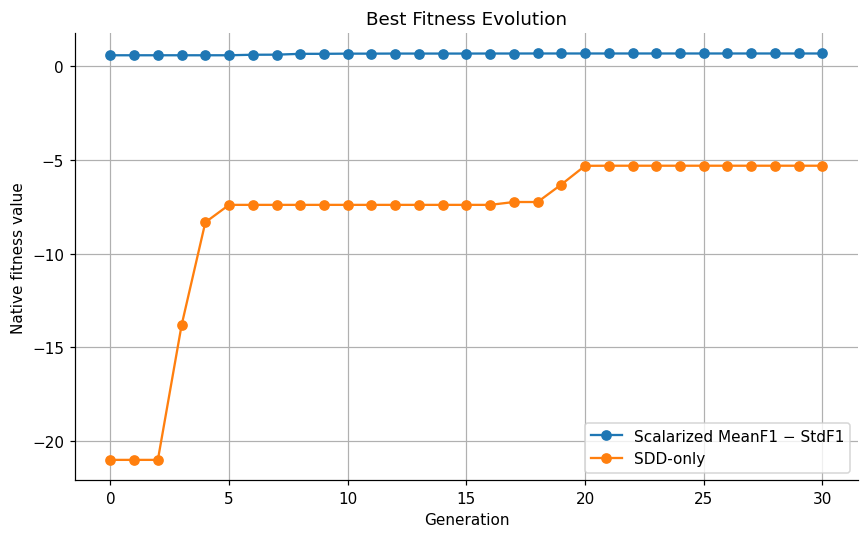

Saved: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs\hard_both_fitness_20260609_2004\fitness_evolution_scalarized.png


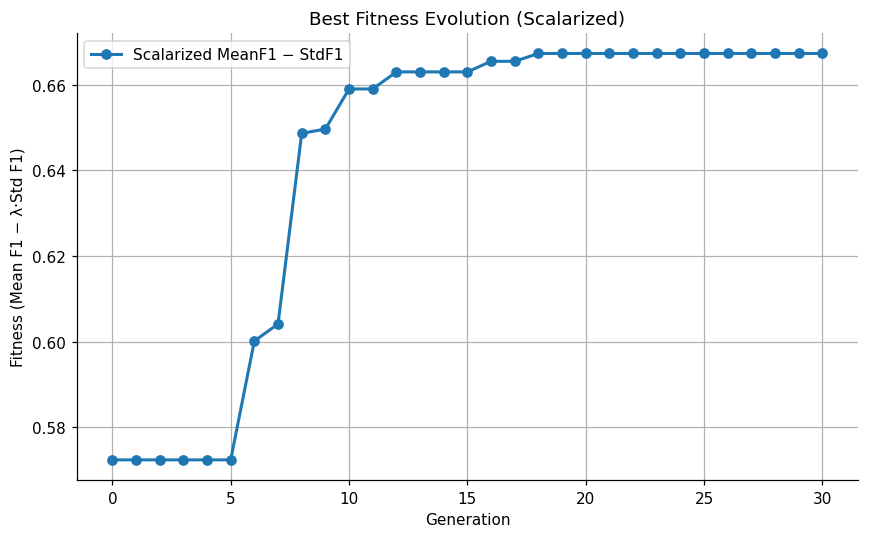

Saved: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs\hard_both_fitness_20260609_2004\fitness_evolution_sdd.png


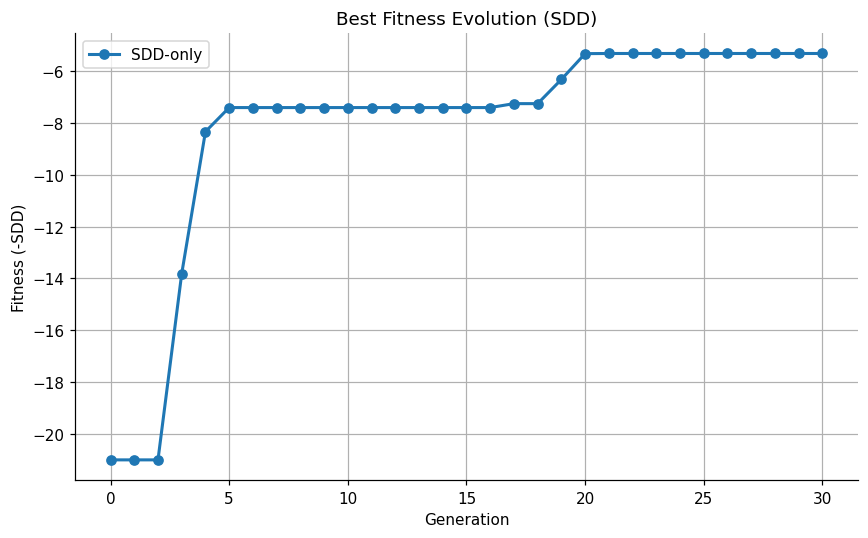

Saved: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs\hard_both_fitness_20260609_2004\fitness_evolution_normalized.png


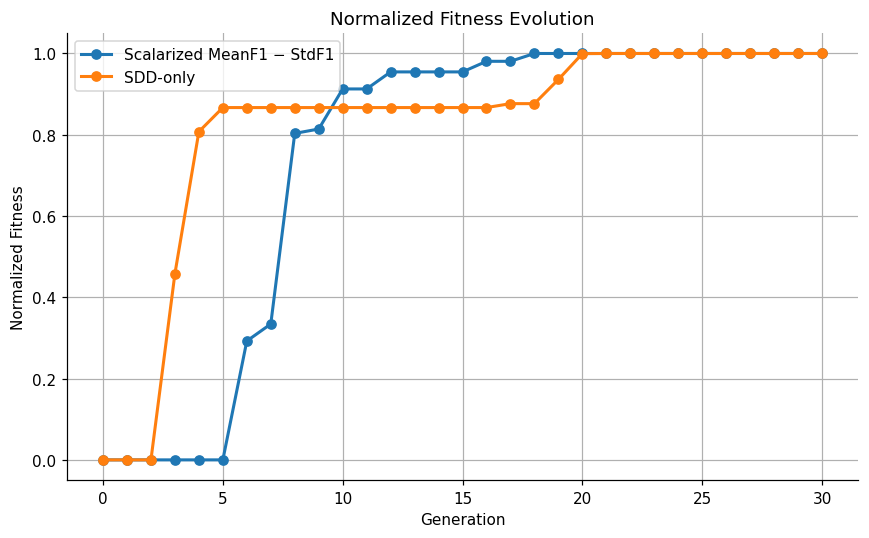

Saved: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs\hard_both_fitness_20260609_2004\unseen_mean_f1_comparison.png


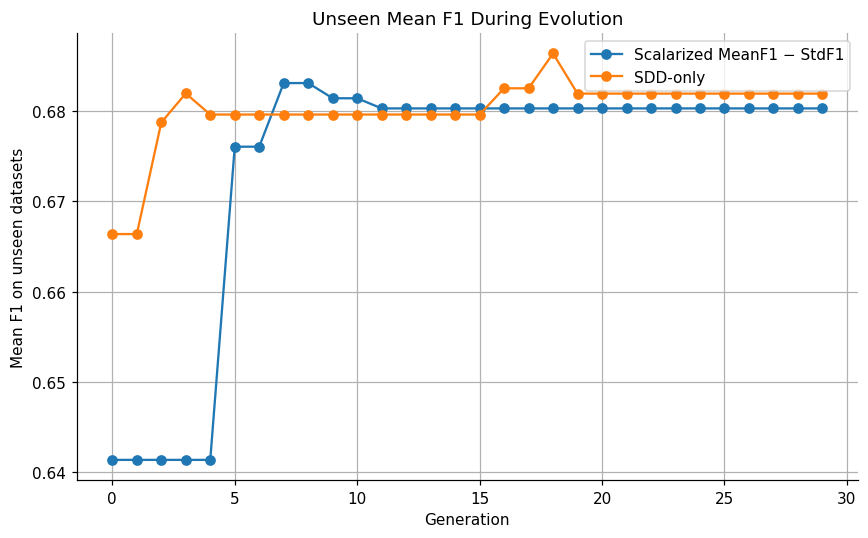

Saved: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs\hard_both_fitness_20260609_2004\unseen_sdd_comparison.png


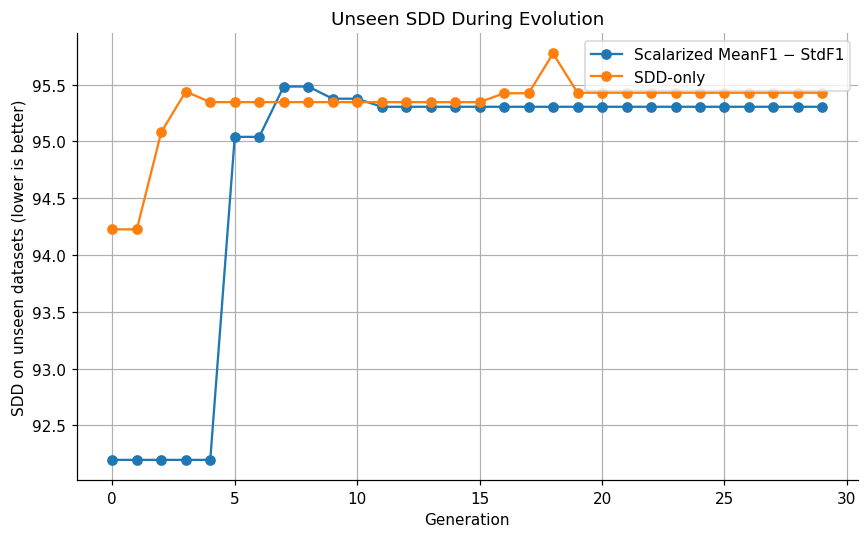

Saved: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs\hard_both_fitness_20260609_2004\tradeoff_unseen_sdd_vs_mean_f1.png


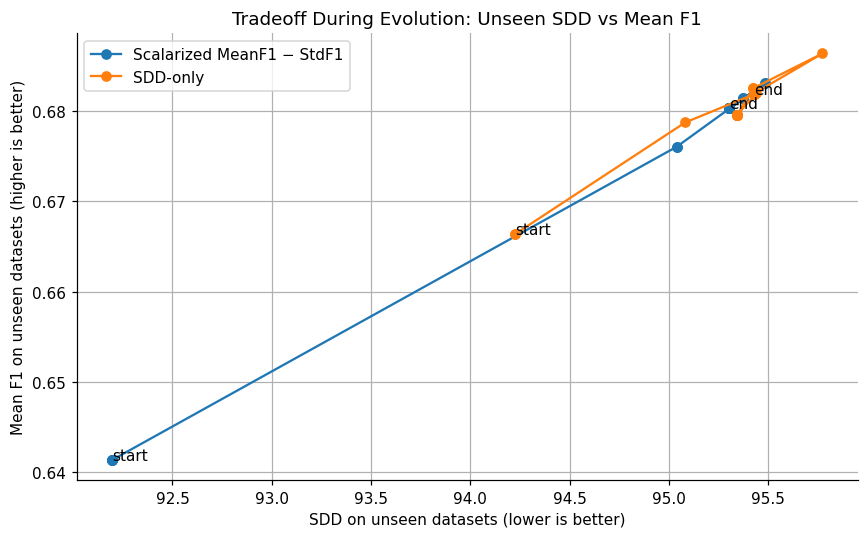

Saved: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs\hard_both_fitness_20260609_2004\generalization_gap_sdd_fitness.png


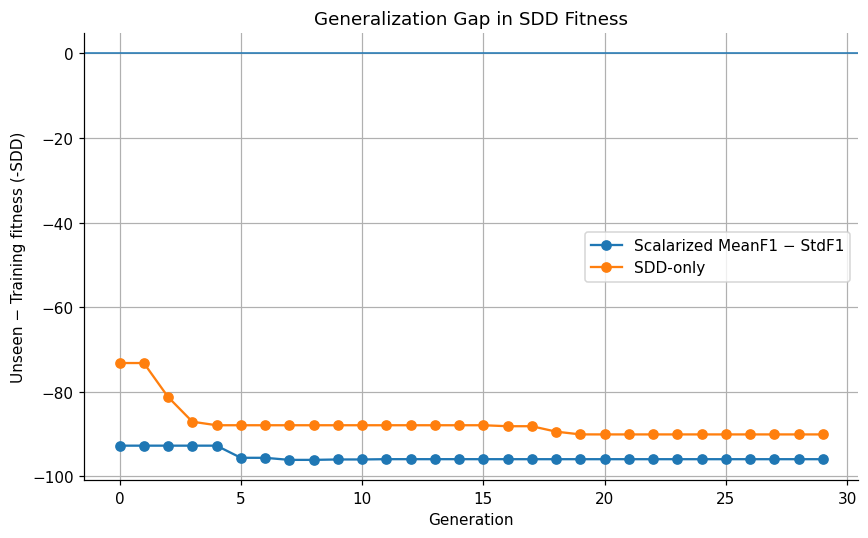

In [5]:
def as_series(history_dict, key):
    values = history_dict.get(key, [])
    return np.asarray(values, dtype=float)


def savefig(name):
    path = results_dir / name
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)


def plot_best_fitness_comparison(results):
    plt.figure()
    for name, r in results.items():
        plt.plot(r["history"], marker="o", label=r["label"])

    plt.title("Best Fitness Evolution")
    plt.xlabel("Generation")
    plt.ylabel("Native fitness value")
    plt.legend()
    savefig("fitness_evolution_comparison.png")
    plt.show()



def plot_best_fitness_separate(results):
    # -------------------------
    # Scalarized Fitness
    # -------------------------
    plt.figure(figsize=(8, 5))

    scalarized = results["scalarized_meanf1_minus_stdf1"]

    plt.plot(
        scalarized["history"],
        marker="o",
        linewidth=2,
        label=scalarized["label"]
    )

    plt.title("Best Fitness Evolution (Scalarized)")
    plt.xlabel("Generation")
    plt.ylabel("Fitness (Mean F1 − λ·Std F1)")
    plt.grid(True)
    plt.legend()

    savefig("fitness_evolution_scalarized.png")
    plt.show()

    # -------------------------
    # SDD Fitness
    # -------------------------
    plt.figure(figsize=(8, 5))

    sdd = results["sdd_only"]

    plt.plot(
        sdd["history"],
        marker="o",
        linewidth=2,
        label=sdd["label"]
    )

    plt.title("Best Fitness Evolution (SDD)")
    plt.xlabel("Generation")
    plt.ylabel("Fitness (-SDD)")
    plt.grid(True)
    plt.legend()

    savefig("fitness_evolution_sdd.png")
    plt.show()


def plot_normalized_fitness_comparison(results):
    plt.figure(figsize=(8, 5))

    for name, r in results.items():
        history = np.array(r["history"])

        normalized = (
            (history - history.min())
            / (history.max() - history.min() + 1e-12)
        )

        plt.plot(
            normalized,
            marker="o",
            linewidth=2,
            label=r["label"]
        )

    plt.title("Normalized Fitness Evolution")
    plt.xlabel("Generation")
    plt.ylabel("Normalized Fitness")
    plt.grid(True)
    plt.legend()

    savefig("fitness_evolution_normalized.png")
    plt.show()


def plot_unseen_mean_f1_comparison(results):
    plt.figure()
    for name, r in results.items():
        best_f1 = as_series(r["generalization_history"], "best")
        plt.plot(best_f1, marker="o", label=r["label"])

    plt.title("Unseen Mean F1 During Evolution")
    plt.xlabel("Generation")
    plt.ylabel("Mean F1 on unseen datasets")
    plt.legend()
    savefig("unseen_mean_f1_comparison.png")
    plt.show()


def plot_unseen_sdd_comparison(results):
    plt.figure()
    for name, r in results.items():
        # Current history stores fitness = -SDD. Convert to positive SDD for interpretability.
        best_sdd = -as_series(r["generalization_sdd_history"], "best")
        plt.plot(best_sdd, marker="o", label=r["label"])

    plt.title("Unseen SDD During Evolution")
    plt.xlabel("Generation")
    plt.ylabel("SDD on unseen datasets (lower is better)")
    plt.legend()
    savefig("unseen_sdd_comparison.png")
    plt.show()


def plot_tradeoff_curve(results):
    plt.figure()
    for name, r in results.items():
        best_f1 = as_series(r["generalization_history"], "best")
        best_sdd = -as_series(r["generalization_sdd_history"], "best")
        n = min(len(best_f1), len(best_sdd))

        plt.plot(best_sdd[:n], best_f1[:n], marker="o", label=r["label"])

        # Annotate start/end so the direction of evolution is clear.
        if n:
            plt.annotate("start", (best_sdd[0], best_f1[0]))
            plt.annotate("end", (best_sdd[n - 1], best_f1[n - 1]))

    plt.title("Tradeoff During Evolution: Unseen SDD vs Mean F1")
    plt.xlabel("SDD on unseen datasets (lower is better)")
    plt.ylabel("Mean F1 on unseen datasets (higher is better)")
    plt.legend()
    savefig("tradeoff_unseen_sdd_vs_mean_f1.png")
    plt.show()


def plot_generalization_gap(results):
    plt.figure()
    for name, r in results.items():
        train_sdd_fitness = as_series(r["fitness_rank_history"], "best")
        unseen_sdd_fitness = as_series(r["generalization_sdd_history"], "best")
        n = min(len(train_sdd_fitness), len(unseen_sdd_fitness))

        # Both are -SDD histories. A large positive/negative gap suggests train/unseen mismatch.
        gap = unseen_sdd_fitness[:n] - train_sdd_fitness[:n]
        plt.plot(gap, marker="o", label=r["label"])

    plt.axhline(0, linewidth=1)
    plt.title("Generalization Gap in SDD Fitness")
    plt.xlabel("Generation")
    plt.ylabel("Unseen − Training fitness (-SDD)")
    plt.legend()
    savefig("generalization_gap_sdd_fitness.png")
    plt.show()


plot_best_fitness_comparison(experiment_results)
plot_best_fitness_separate(experiment_results)
plot_normalized_fitness_comparison(experiment_results)
plot_unseen_mean_f1_comparison(experiment_results)
plot_unseen_sdd_comparison(experiment_results)
plot_tradeoff_curve(experiment_results)
plot_generalization_gap(experiment_results)

## 6. Final evaluation of each winning gene on the training datasets

In [6]:
def get_eval_function(module_name):
    module = importlib.import_module(module_name)
    fn = getattr(module, "_eval_one_algo_all_datasets", None)
    loader = getattr(module, "_load_dataset_csv", None)
    return fn, loader


def final_evaluate_gene(exp_name, result):
    eval_fn, loader = get_eval_function(result["module"])

    datasets_info = []
    for ds_name, ds_path in datasets.items():
        target_col = target_cols.get(ds_name, None)
        datasets_info.append((ds_name, str(ds_path), target_col))

    dataset_split_seeds = {
        ds_name: stable_dataset_seed(SEED, ds_name)
        for ds_name in datasets.keys()
    }

    # Prefer the same internal evaluator as the evolutionary module.
    if eval_fn is not None:
        out = eval_fn(
            algo_genome=result["best_gene"],
            datasets_info=datasets_info,
            n_splits=k_folds_final,
            dataset_split_seeds=dataset_split_seeds,
            bad_score=0.0,
            timeout_s=timeout_s,
        )
        return out

    # Fallback for modules that do not expose _eval_one_algo_all_datasets.
    if loader is None:
        raise AttributeError(
            f"{result['module']} has neither _eval_one_algo_all_datasets nor _load_dataset_csv."
        )

    fallback_results = {}
    for ds_name, ds_path in datasets.items():
        target_col = target_cols.get(ds_name, None)
        X, y = loader(ds_path, target_col=target_col)
        fallback_results[ds_name] = eval_gene_on_dataset(
            result["best_gene"], X, y, k=k_folds_final, seed=dataset_split_seeds[ds_name]
        ).tolist()

    return {
        "results": fallback_results,
        "times": {ds: {"total": np.nan, "fit": np.nan} for ds in fallback_results},
        "structures": {ds: {"depth": np.nan, "nodes": np.nan} for ds in fallback_results},
        "infeasible": False,
        "failed_dataset": None,
        "failure_reason": None,
    }


summary_rows = []
detail_rows = []

for exp_name, result in experiment_results.items():
    print(f"\n===== FINAL EVALUATION: {result['label']} =====")
    print("Gene:", result["best_gene"])

    out = final_evaluate_gene(exp_name, result)
    scores_by_dataset = out["results"]
    metrics = summarize_scores_by_dataset(scores_by_dataset)

    summary_rows.append({
        "experiment": exp_name,
        "label": result["label"],
        "gene": result["best_gene"],
        "mean_f1_across_datasets": metrics["mean_f1"],
        "raw_std_f1_across_datasets": metrics["raw_std_f1"],
        "xi_sdd_across_datasets": metrics["xi_sdd"],
        "fitness_mean_f1_minus_std": metrics["fitness_mean_f1_minus_std"],
        "fitness_minus_xi_sdd": metrics["fitness_minus_xi_sdd"],
        "infeasible": out.get("infeasible"),
        "failed_dataset": out.get("failed_dataset"),
        "failure_reason": out.get("failure_reason"),
    })

    for ds, scores in scores_by_dataset.items():
        scores = clean_scores(scores)
        times = out.get("times", {}).get(ds, {})
        struct = out.get("structures", {}).get(ds, {})

        detail_rows.append({
            "experiment": exp_name,
            "label": result["label"],
            "dataset": ds,
            "mean_f1": float(np.mean(scores)) if scores else 0.0,
            "std_f1_folds": float(np.std(scores)) if scores else 0.0,
            "best_fold_f1": float(np.max(scores)) if scores else 0.0,
            "worst_fold_f1": float(np.min(scores)) if scores else 0.0,
            "fold_scores": scores,
            "total_time_s": times.get("total", np.nan),
            "fit_time_s": times.get("fit", np.nan),
            "mean_depth": struct.get("depth", np.nan),
            "mean_nodes": struct.get("nodes", np.nan),
        })

final_summary_df = pd.DataFrame(summary_rows)
final_details_df = pd.DataFrame(detail_rows)

display(final_summary_df)
display(final_details_df.sort_values(["experiment", "mean_f1"], ascending=[True, False]))

final_summary_df.to_csv(results_dir / "final_summary.csv", index=False)
final_details_df.to_csv(results_dir / "final_details.csv", index=False)


===== FINAL EVALUATION: Scalarized MeanF1 − StdF1 =====
Gene: [0, 1, 9, 1, 5, 0, 2, 1]

===== FINAL EVALUATION: SDD-only =====
Gene: [9, 1, 8, 3, 0, 1, 3, 1]


,experiment,label,gene,mean_f1_across_datasets,raw_std_f1_across_datasets,xi_sdd_across_datasets,fitness_mean_f1_minus_std,fitness_minus_xi_sdd,infeasible,failed_dataset,failure_reason
0,scalarized_meanf1_minus_stdf1,Scalarized MeanF1 − StdF1,"[0, 1, 9, 1, 5, 0, 2, 1]",0.722256,0.018968,0.029792,0.703288,-0.029792,False,None,None
1,sdd_only,SDD-only,"[9, 1, 8, 3, 0, 1, 3, 1]",0.643504,0.042291,0.073636,0.601213,-0.073636,False,None,None


,experiment,label,dataset,mean_f1,std_f1_folds,best_fold_f1,worst_fold_f1,fold_scores,total_time_s,fit_time_s,mean_depth,mean_nodes
1,scalarized_meanf1_minus_stdf1,Scalarized MeanF1 − StdF1,sonar,0.742773,0.056137,0.828861,0.663616,"[0.7619047619047619, 0.6636155606407322, 0.703...",14.607544,14.573556,11.0,102.2
0,scalarized_meanf1_minus_stdf1,Scalarized MeanF1 − StdF1,semeion,0.728947,0.014232,0.747099,0.707953,"[0.7470992696919515, 0.7312713452719525, 0.740...",490.282510,490.190734,11.0,568.2
3,scalarized_meanf1_minus_stdf1,Scalarized MeanF1 − StdF1,cylinder_bands,0.726022,0.047729,0.776920,0.638796,"[0.7381230354737315, 0.7769196228109565, 0.718...",11.773519,11.726973,11.0,154.2
2,scalarized_meanf1_minus_stdf1,Scalarized MeanF1 − StdF1,glass,0.691284,0.047602,0.777564,0.652564,"[0.7775641025641026, 0.7075268817204301, 0.652...",4.597349,4.565410,11.0,193.8
7,sdd_only,SDD-only,cylinder_bands,0.688638,0.027882,0.736090,0.648625,"[0.6883116883116883, 0.6871905073343922, 0.736...",7.969585,7.921874,10.0,63.0
4,sdd_only,SDD-only,semeion,0.667928,0.028685,0.700260,0.624429,"[0.6594953918082316, 0.6563538344159268, 0.700...",200.031698,199.932973,10.0,281.8
5,sdd_only,SDD-only,sonar,0.641140,0.040572,0.707143,0.590000,"[0.6597222222222223, 0.6111111111111112, 0.637...",13.554056,13.519883,10.0,81.4
6,sdd_only,SDD-only,glass,0.576310,0.084916,0.700813,0.453994,"[0.5228725749559083, 0.5752688172043011, 0.628...",3.025763,2.993393,10.0,113.4


## 7. Final-evaluation plots

Saved: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs\hard_both_fitness_20260609_2004\final_mean_f1_across_datasets.png


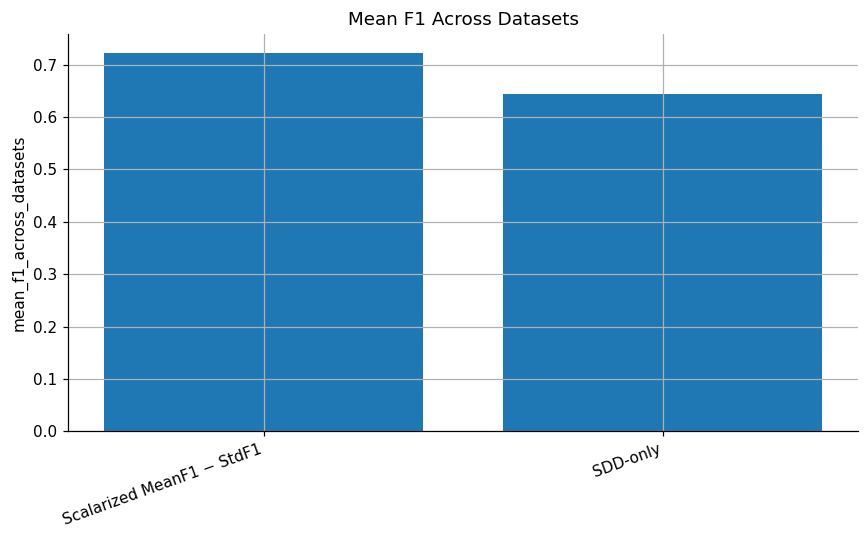

Saved: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs\hard_both_fitness_20260609_2004\final_raw_std_f1_across_datasets.png


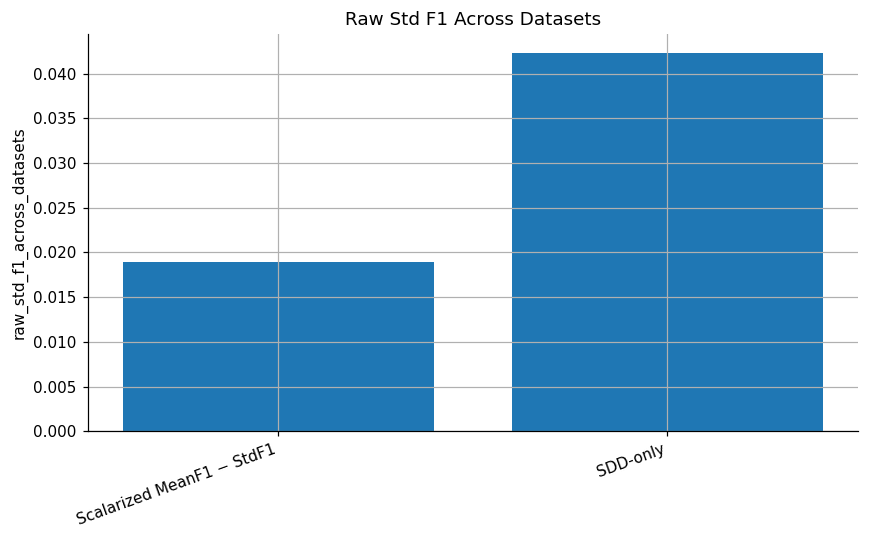

Saved: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs\hard_both_fitness_20260609_2004\final_xi_sdd_across_datasets.png


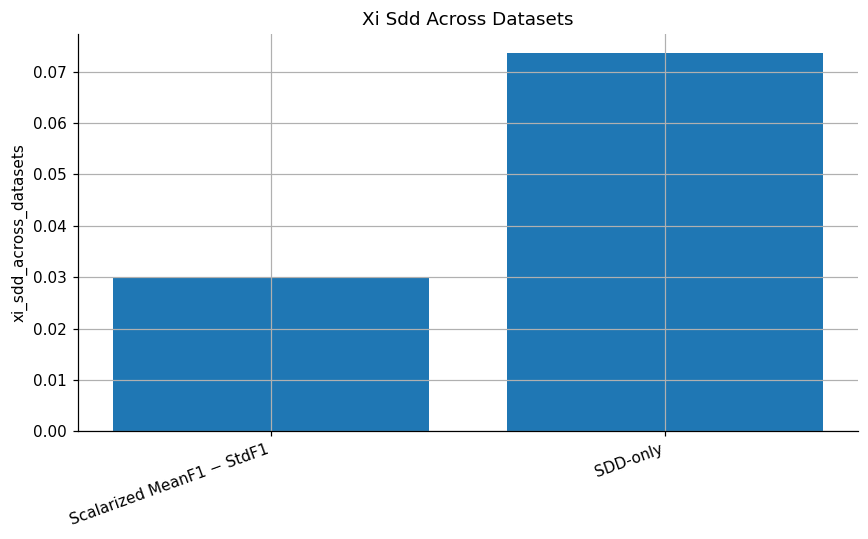

Saved: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs\hard_both_fitness_20260609_2004\final_fitness_mean_f1_minus_std.png


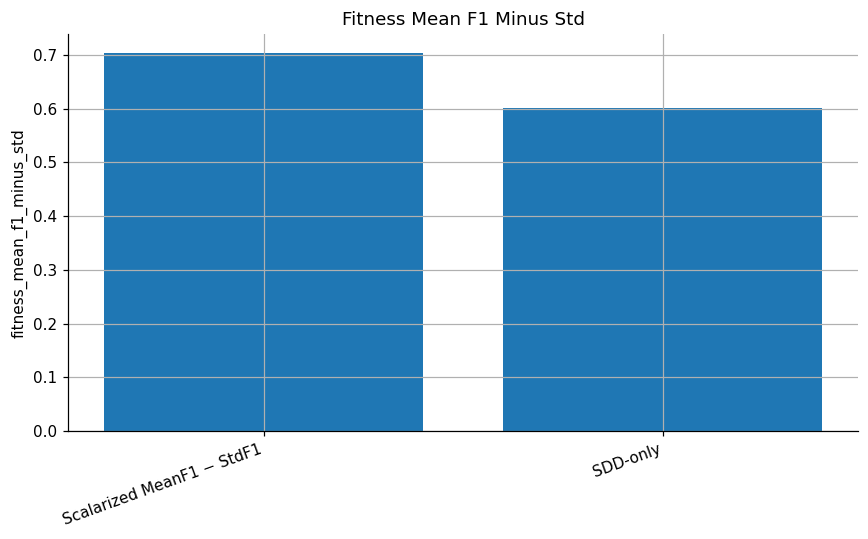

Saved: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs\hard_both_fitness_20260609_2004\final_fitness_minus_xi_sdd.png


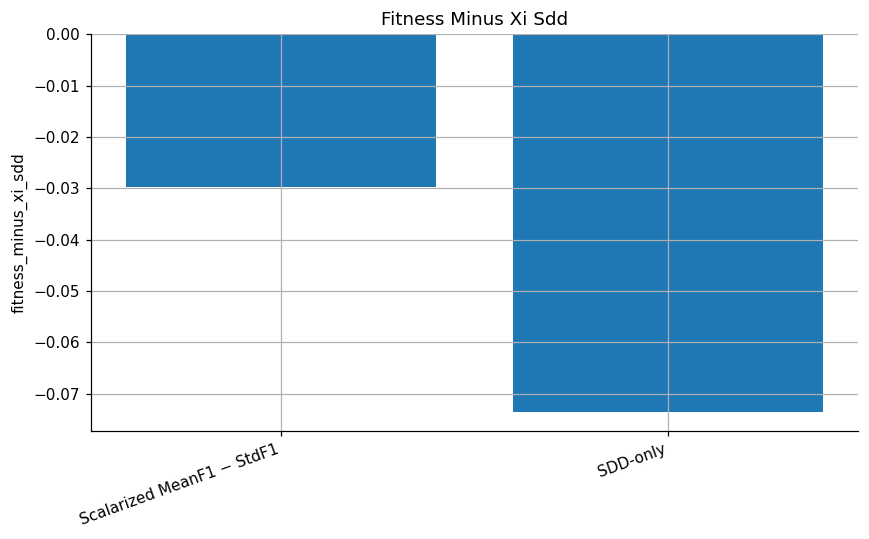

Saved: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs\hard_both_fitness_20260609_2004\final_dataset_f1_heatmap.png


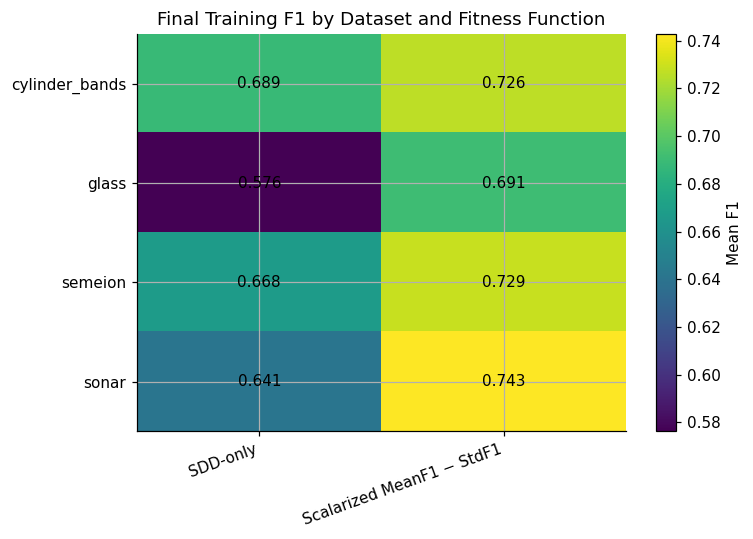

Saved: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs\hard_both_fitness_20260609_2004\final_winners_sdd_vs_mean_f1.png


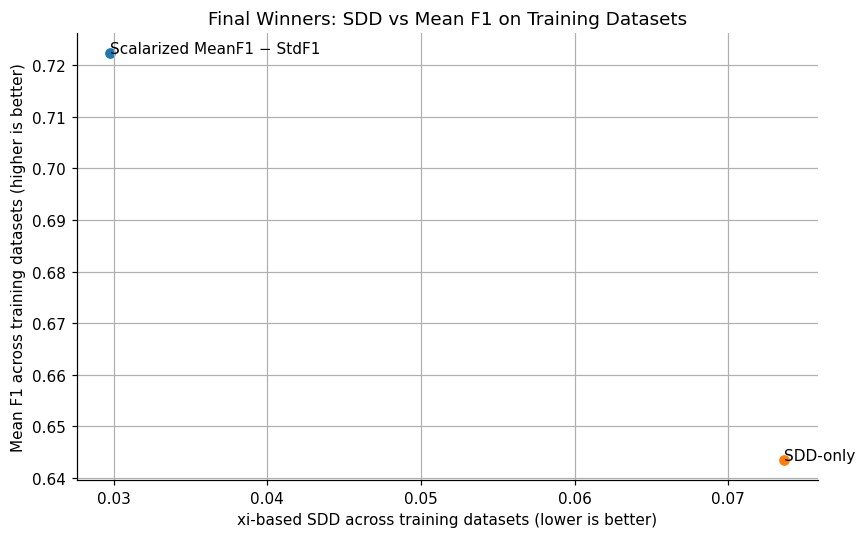

In [7]:
def plot_final_metric_bars(summary_df):
    metric_cols = [
        "mean_f1_across_datasets",
        "raw_std_f1_across_datasets",
        "xi_sdd_across_datasets",
        "fitness_mean_f1_minus_std",
        "fitness_minus_xi_sdd",
    ]

    for metric in metric_cols:
        plt.figure()
        plt.bar(summary_df["label"], summary_df[metric])
        plt.title(metric.replace("_", " ").title())
        plt.ylabel(metric)
        plt.xticks(rotation=20, ha="right")
        savefig(f"final_{metric}.png")
        plt.show()


def plot_dataset_f1_heatmap(details_df):
    pivot = details_df.pivot(index="dataset", columns="label", values="mean_f1")

    plt.figure(figsize=(7, 5))
    image = plt.imshow(pivot.values, aspect="auto")
    plt.colorbar(image, label="Mean F1")
    plt.xticks(range(len(pivot.columns)), pivot.columns, rotation=20, ha="right")
    plt.yticks(range(len(pivot.index)), pivot.index)
    plt.title("Final Training F1 by Dataset and Fitness Function")

    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            value = pivot.values[i, j]
            plt.text(j, i, f"{value:.3f}", ha="center", va="center")

    savefig("final_dataset_f1_heatmap.png")
    plt.show()


def plot_final_tradeoff(summary_df):
    plt.figure()
    for _, row in summary_df.iterrows():
        plt.scatter(row["xi_sdd_across_datasets"], row["mean_f1_across_datasets"])
        plt.annotate(row["label"], (row["xi_sdd_across_datasets"], row["mean_f1_across_datasets"]))

    plt.title("Final Winners: SDD vs Mean F1 on Training Datasets")
    plt.xlabel("xi-based SDD across training datasets (lower is better)")
    plt.ylabel("Mean F1 across training datasets (higher is better)")
    savefig("final_winners_sdd_vs_mean_f1.png")
    plt.show()


plot_final_metric_bars(final_summary_df)
plot_dataset_f1_heatmap(final_details_df)
plot_final_tradeoff(final_summary_df)

## Notes

The most useful new plot is **Tradeoff During Evolution: Unseen SDD vs Mean F1**. It shows whether the run is improving average performance, consistency, or both.

The **Final Winners: SDD vs Mean F1** scatter is also useful because it directly compares the winning genes from the two fitness functions on the same training evaluation protocol.